# test2: FFT座標シフトと共通因子によるコア加算

このノートブックは `test.ipynb` から独立した最小例です。2本のThreadを複数Besselモードで作り、フーリエ変換後の移動位相、コア再射影、共通因子による復元を確認します。**位相のみのSLM符号化・4f系は含めません**。FFTの座標移動は周期境界を仮定し、固定開口の直接生成との差も別に表示します。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0

# 小さめの例。全ての値をこのセルで変更できます。
N = 256
DX = 8e-6                 # 出力面の画素ピッチ [m]
RANK = 80
KR = np.array([75_000., 95_000., 111_000.])  # [rad/m]
SHIFTS_PX = [(0, 0), (12, -9)]                 # (x, y) [pixel]
WEIGHTS = np.array([[1.0, 0.7, 0.4], [0.8, 1.0, 0.6]])
assert WEIGHTS.shape == (len(SHIFTS_PX), len(KR))

x = (np.arange(N) - N//2) * DX
X, Y = np.meshgrid(x, x)
radius = np.hypot(X, Y)
# 緩やかな固定開口。FFTの周期シフトと物理的な固定開口の違いを見せる。
edge = np.clip((np.abs(x) - 0.85*np.max(np.abs(x))) /
               (0.15*np.max(np.abs(x))), 0, 1)
aperture = np.outer(0.5*(1+np.cos(np.pi*edge)),
                    0.5*(1+np.cos(np.pi*edge)))
fields = np.array([j0(k*radius)*aperture for k in KR])
spectra = np.fft.fft2(fields, norm="ortho", axes=(-2, -1))
kx = 2*np.pi*np.fft.fftfreq(N, DX)
ky = 2*np.pi*np.fft.fftfreq(N, DX)
print(f"beam count={len(KR)}, image={N}x{N}, rank={RANK}")


beam count=3, image=256x256, rank=80


## 1. 全モードで共通の因子行列を作る

実部と虚部を並べた行列のSVDから、周波数の縦方向 (U_y) と横方向 (U_x) を作ります。保存するモード別の量は (C_i=U_y^T F_i U_x) です。ここでは説明のためSVDで辞書を作り、既存の巨大な圧縮ファイルは読み込みません。


In [2]:
# 実部・虚部の双方から実数の共通基底を作る。
Y_training = np.concatenate(
    [part for F in spectra for part in (F.real, F.imag)], axis=1)
X_training = np.concatenate(
    [part for F in spectra for part in (F.real.T, F.imag.T)], axis=1)
Uy = np.linalg.svd(Y_training, full_matrices=False)[0][:, :RANK]
Ux = np.linalg.svd(X_training, full_matrices=False)[0][:, :RANK]
cores = np.array([Uy.T @ F @ Ux for F in spectra])

def relative_error(reference, estimate):
    return np.linalg.norm(reference-estimate) / np.linalg.norm(reference)

center_errors = [relative_error(F, Uy @ C @ Ux.T)
                 for F, C in zip(spectra, cores)]
print("圧縮前の各モードのFFT再現誤差:", np.array(center_errors))


圧縮前の各モードのFFT再現誤差: [3.13166677e-15 3.44603090e-15 3.69579458e-15]


## 2. 座標をずらすとFFTには位相が掛かる

(Delta x=s_xDX, Delta y=s_yDX) のとき、(F_{
m shift}=D_y F D_x) です。(D_y) と (D_x) は周波数ごとに異なる対角位相です。**コアに1個の定数を掛ける操作ではありません**。共通基底に戻したコアは (C_{
m shift}=A_y C A_x)、(A_y=U_y^T D_y U_y)、(A_x=U_x^T D_x U_x) となります。元の基底からはみ出す成分があるため、これは一般には近似です。


In [3]:
full_sum = np.zeros((N, N), dtype=complex)
shifted_core_sum = np.zeros((RANK, RANK), dtype=complex)
fixed_aperture_sum = np.zeros((N, N), dtype=complex)
example = None

for thread, (sx, sy) in enumerate(SHIFTS_PX):
    # 同じThread内のモードは同じ座標だけ移動する。
    dy = np.exp(-1j*ky*sy*DX)
    dx = np.exp(-1j*kx*sx*DX)
    Ay = Uy.T @ (dy[:, None]*Uy)
    Ax = Ux.T @ (dx[:, None]*Ux)
    centered_core = np.tensordot(WEIGHTS[thread], cores, axes=(0, 0))
    shifted_core_sum += Ay @ centered_core @ Ax

    for mode, k in enumerate(KR):
        full_shift = dy[:, None]*spectra[mode]*dx[None, :]
        full_sum += WEIGHTS[thread, mode]*full_shift
        fixed_aperture_sum += WEIGHTS[thread, mode]*(
            j0(k*np.hypot(X-sx*DX, Y-sy*DX))*aperture)
        if thread == 1 and mode == 2:
            example = (sx, sy, dy, dx, spectra[mode],
                       full_shift, cores[mode], Ay@cores[mode]@Ax)

reconstructed_fft = Uy @ shifted_core_sum @ Ux.T
periodic_field = np.fft.ifft2(full_sum, norm="ortho")
reconstructed_field = np.fft.ifft2(reconstructed_fft, norm="ortho")
sx, sy, dy, dx, original_fft, shifted_fft, original_core, shifted_core = example
example_fft_rec = Uy @ shifted_core @ Ux.T
shifted_field_by_roll = np.roll(fields[2], shift=(sy, sx), axis=(0, 1))

print("FFT移動定理の誤差:",
      relative_error(np.fft.fft2(shifted_field_by_roll, norm="ortho"), shifted_fft))
print("加算後の共通基底復元誤差（FFT）:",
      relative_error(full_sum, reconstructed_fft))
print("加算後の共通基底復元誤差（実空間）:",
      relative_error(periodic_field, reconstructed_field))
print("固定開口の直接生成 vs FFT周期シフト:",
      relative_error(fixed_aperture_sum, periodic_field))


FFT移動定理の誤差: 1.3982874396423511e-15
加算後の共通基底復元誤差（FFT）: 0.6523905468354654
加算後の共通基底復元誤差（実空間）: 0.6523905468354654
固定開口の直接生成 vs FFT周期シフト: 0.16888748208335264


## 3. 一枚の図で追う

上段は1モードのFFTと移動位相、中段はコアとFFTの再射影、下段は複数Threadの合成です。周波数図だけ円環付近に表示を拡大します。振幅比較は同じカラースケールです。差分の色は差分専用スケールです。


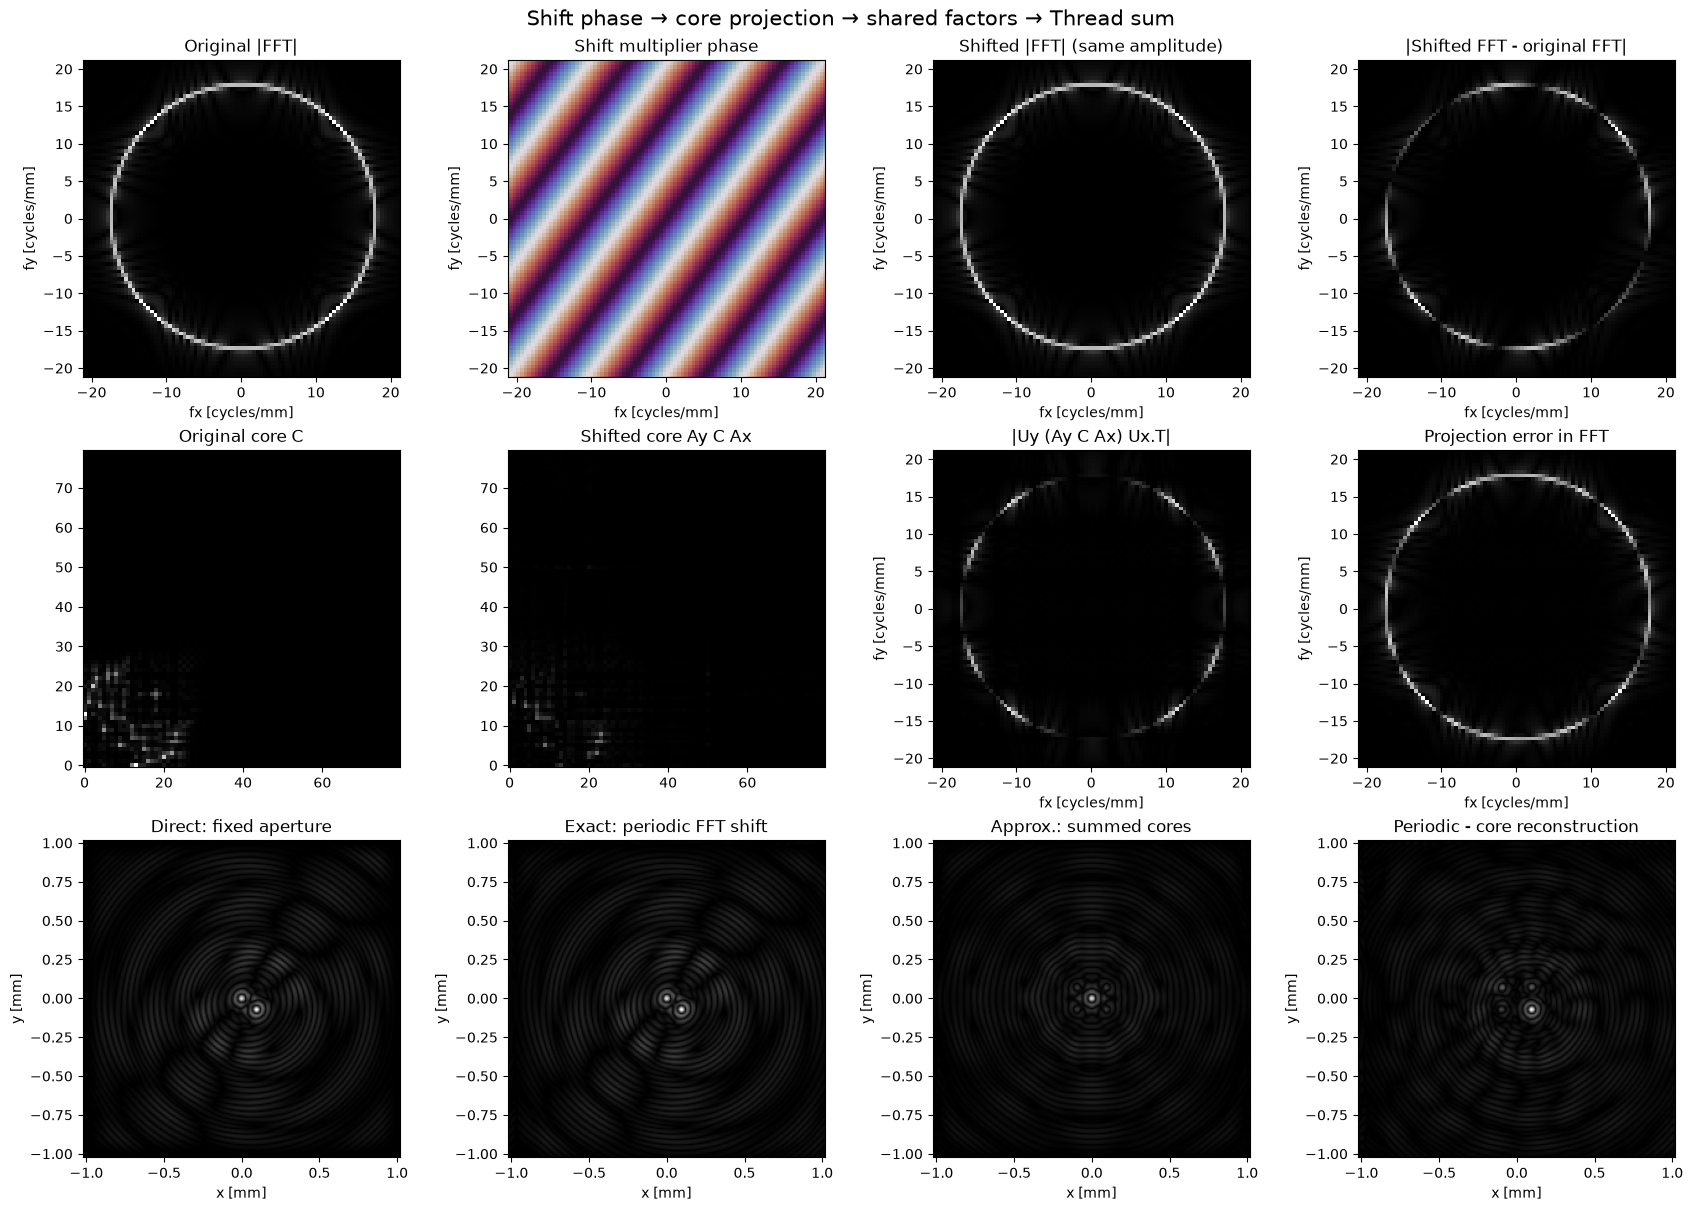

In [4]:
fig, ax = plt.subplots(3, 4, figsize=(17, 12), constrained_layout=True)
fft_extent = np.array([-1, 1, -1, 1])/(2*DX*1e3)  # cycles/mm
space_extent = [x[0]*1e3, x[-1]*1e3, x[0]*1e3, x[-1]*1e3]
freq_zoom = 1.2*KR[2]/(2*np.pi*1e3)

def fft_image(axis, array, title, *, cmap="gray", vmin=None, vmax=None):
    axis.imshow(np.fft.fftshift(array), origin="lower", extent=fft_extent,
                cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    axis.set(xlim=(-freq_zoom, freq_zoom), ylim=(-freq_zoom, freq_zoom),
             xlabel="fx [cycles/mm]", ylabel="fy [cycles/mm]", title=title)

spectrum_max = max(np.abs(original_fft).max(), np.abs(shifted_fft).max())
fft_image(ax[0, 0], np.abs(original_fft)/spectrum_max, "Original |FFT|",
          vmin=0, vmax=1)
fft_image(ax[0, 1], np.angle(dy[:, None]*dx[None, :]),
          "Shift multiplier phase", cmap="twilight", vmin=-np.pi, vmax=np.pi)
fft_image(ax[0, 2], np.abs(shifted_fft)/spectrum_max,
          "Shifted |FFT| (same amplitude)", vmin=0, vmax=1)
fft_image(ax[0, 3], np.abs(shifted_fft-original_fft)/spectrum_max,
          "|Shifted FFT - original FFT|")

core_max = max(np.abs(original_core).max(), np.abs(shifted_core).max())
ax[1, 0].imshow(np.abs(original_core)/core_max, cmap="gray",
                origin="lower", vmin=0, vmax=1)
ax[1, 0].set_title("Original core C")
ax[1, 1].imshow(np.abs(shifted_core)/core_max, cmap="gray",
                origin="lower", vmin=0, vmax=1)
ax[1, 1].set_title("Shifted core Ay C Ax")
fft_image(ax[1, 2], np.abs(example_fft_rec)/spectrum_max,
          "|Uy (Ay C Ax) Ux.T|", vmin=0, vmax=1)
fft_image(ax[1, 3], np.abs(shifted_fft-example_fft_rec)/spectrum_max,
          "Projection error in FFT")
spatial_scale = max(np.abs(periodic_field).max(),
                    np.abs(reconstructed_field).max())
for axis, field, title in zip(
    ax[2, :3],
    [fixed_aperture_sum, periodic_field, reconstructed_field],
    ["Direct: fixed aperture", "Exact: periodic FFT shift",
     "Approx.: summed cores"]):
    axis.imshow(np.abs(field)/spatial_scale, origin="lower",
                extent=space_extent, cmap="gray", vmin=0, vmax=1)
    axis.set(xlabel="x [mm]", ylabel="y [mm]", title=title)
ax[2, 3].imshow(np.abs(periodic_field-reconstructed_field)/spatial_scale,
                origin="lower", extent=space_extent, cmap="gray")
ax[2, 3].set(xlabel="x [mm]", ylabel="y [mm]",
             title="Periodic - core reconstruction")
fig.suptitle("Shift phase → core projection → shared factors → Thread sum",
             fontsize=15)
plt.show()
